# Residual-Based Drift Detector with Adaptive Conformal Intervals: Evaluation & Benchmark Comparison

In [1]:
# Import required libraries
import sys
import os
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# Add parent directory to path
sys.path.append(os.path.abspath(os.path.join('..')))

# Import project custom modules
from src.detector.residual_detector import ResidualConformalDriftDetector
from src.detector.run_residual_detector_evaluation import evaluate_residual_detector

# Styling setup
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 2. Load Baseline Results & Benchmark Manifest

In [2]:
data_dir = "../data"
processed_dir = Path(data_dir) / "processed"
manifest_path = processed_dir / "benchmark_manifest.json"
baseline_results_path = processed_dir / "baseline_evaluation_results.csv"

# 1. Load classic baseline evaluation results
df_baseline = pd.read_csv(baseline_results_path)
print(f"Loaded baseline results shape: {df_baseline.shape}")
display(df_baseline.head())

# 2. Load benchmark manifest

with open(manifest_path, "r") as f:
    benchmark_manifest = json.load(f)

print(f"Total benchmark scenarios in manifest: {len(benchmark_manifest)}")

Loaded baseline results shape: (180, 15)


,dataset,series_id,seasonality_strength,seasonality_group,level,drift_type,magnitude,method,false_alarms,far_per_1000,precision,recall,f1_score,detection_delay,detected
0,alibaba_cluster_trace,default_series,NaN,unknown,1,none,0.0,ks,56,24.966563,0.0,0.0,0.0,NaN,0
1,alibaba_cluster_trace,default_series,NaN,unknown,1,none,0.0,psi,82,36.558181,0.0,0.0,0.0,NaN,0
2,alibaba_cluster_trace,default_series,NaN,unknown,1,none,0.0,wasserstein,72,32.099866,0.0,0.0,0.0,NaN,0
3,alibaba_cluster_trace,default_series,NaN,unknown,1,none,0.0,adwin,15,6.687472,0.0,0.0,0.0,NaN,0
4,alibaba_cluster_trace,default_series,NaN,unknown,1,none,0.0,page_hinkley,26,11.591618,0.0,0.0,0.0,NaN,0


Total benchmark scenarios in manifest: 30


## 3. Run ResidualConformalDriftDetector on Benchmarks

In [3]:
# Execute evaluation
df_residual = evaluate_residual_detector(benchmark_manifest, processed_dir)
display(df_residual.head())

Skipping non-seasonal dataset: seismic_iquique_random


,dataset,series_id,seasonality_strength,seasonality_group,level,drift_type,magnitude,method,false_alarms,far_per_1000,precision,recall,f1_score,detection_delay,detected
0,alibaba_cluster_trace,default_series,NaN,unknown,1,none,0.0,residual_conformal,32,14.266607,0.000000,0.0,0.000000,NaN,0.0
1,alibaba_cluster_trace,default_series,NaN,unknown,2,abrupt,0.5,residual_conformal,27,NaN,0.035714,1.0,0.068966,32.0,1.0
2,alibaba_cluster_trace,default_series,NaN,unknown,2,abrupt,1.0,residual_conformal,26,NaN,0.037037,1.0,0.071429,32.0,1.0
3,alibaba_cluster_trace,default_series,NaN,unknown,2,abrupt,2.0,residual_conformal,27,NaN,0.035714,1.0,0.068966,32.0,1.0
4,alibaba_cluster_trace,default_series,NaN,unknown,2,abrupt,3.0,residual_conformal,24,NaN,0.040000,1.0,0.076923,37.0,1.0


## 4. Combine Results & Compare with Classic Methods

In [4]:
# Combine baseline and residual conformal detector results
df_comparison = pd.concat([df_baseline, df_residual], ignore_index=True)

# Save combined comparison results
df_comparison.to_csv(processed_dir / "full_detector_comparison_results.csv", index=False)

df_comparison_level_1 = df_comparison[df_comparison['level'] == 1][["dataset", "level", "drift_type", "method", "false_alarms", "far_per_1000"]]
df_comparison_level_2 = df_comparison[df_comparison['level'] == 2][["dataset", "level", "drift_type", "magnitude", "method", "precision", "recall", "f1_score", "detection_delay", "detected"]]
df_comparison_level_3 = df_comparison[(df_comparison['level'] == 3) & (~df_comparison['dataset'].isin(["seismic_iquique_trace"]))][["dataset", "level", "drift_type", "method", "precision", "recall", "f1_score", "detection_delay", "detected"]]

## 5. Comparative Visualization

### 5.1 Level 1 Analysis: False Alarm Rate (FAR)

In [5]:
print("=== Level 1: Drift-Free False Alarm Summary ===")
summary_level_1 = df_comparison_level_1.groupby("method")[["false_alarms", "far_per_1000"]].mean().reset_index()
display(summary_level_1)

=== Level 1: Drift-Free False Alarm Summary ===


,method,false_alarms,far_per_1000
0,adwin,8.25,2.230433
1,ks,39.00,9.918419
2,kswin,29.00,4.595452
3,page_hinkley,340.00,27.533235
4,psi,366.75,29.823977
5,residual_conformal,64.25,7.705652
6,wasserstein,413.25,33.460405


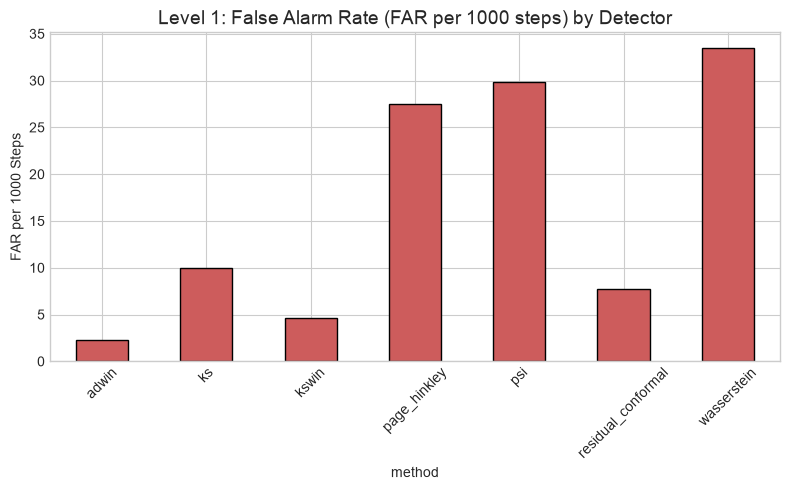

In [6]:
# Level 1 Plot: False Alarms by Detector
fig, ax = plt.subplots(figsize=(8, 5))
summary_level_1.set_index("method")["far_per_1000"].plot(kind="bar", ax=ax, color="indianred", edgecolor="black")
ax.set_title("Level 1: False Alarm Rate (FAR per 1000 steps) by Detector", fontsize=14)
ax.set_ylabel("FAR per 1000 Steps")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 5.2 Level 2 & 3 Analysis: Detection Performance

In [7]:
# Combine Level 2 and 3 for overall detection capability evaluation
df_comparison_levels_2_3 = pd.concat([df_comparison_level_2, df_comparison_level_3])

print("\n=== Level 2 & 3: Detection Performance Summary ===")
summary_levels_2_3 = df_comparison_levels_2_3.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_2_3)


=== Level 2 & 3: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.030110,0.015638,0.423077,33.181818
1,ks,0.028072,0.014720,0.961538,10.560000
2,kswin,0.047800,0.026463,0.807692,39.190476
3,page_hinkley,0.023602,0.012223,0.846154,14.272727
4,psi,0.018722,0.009722,1.000000,10.307692
5,residual_conformal,0.077409,0.059306,1.000000,19.240000
6,wasserstein,0.019998,0.010377,1.000000,10.307692


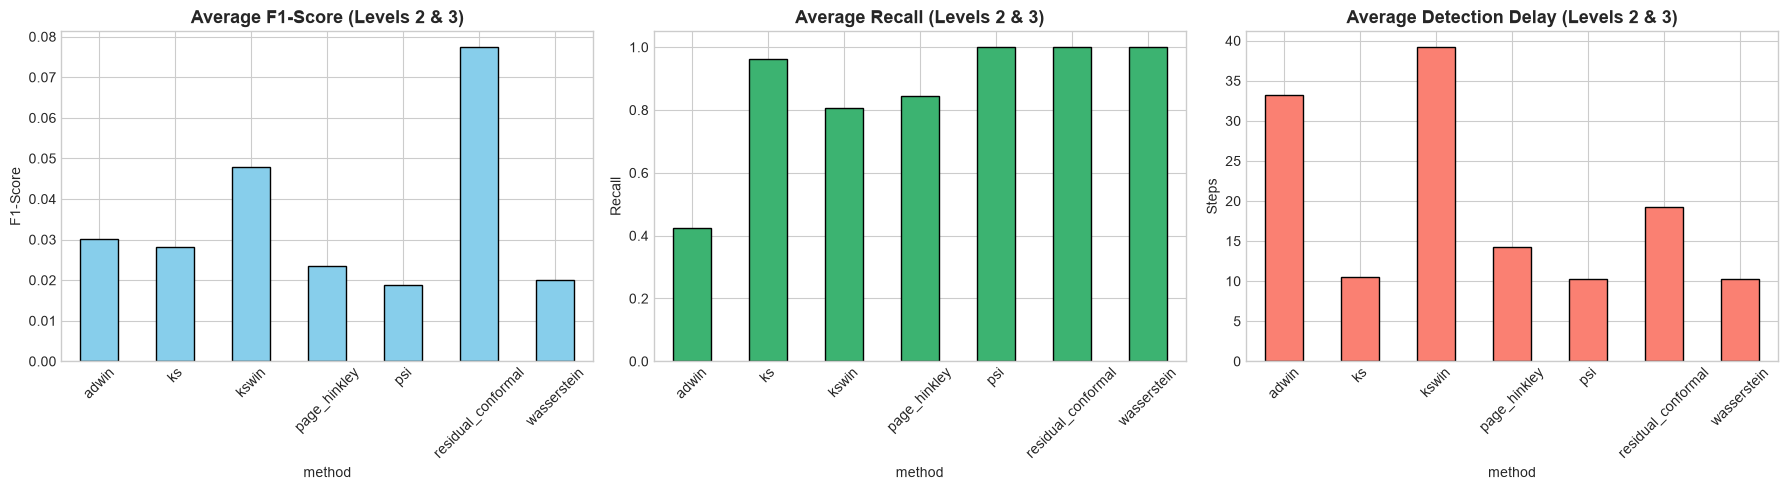

In [8]:
# Level 2 & 3 Plots: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_2_3.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_2_3.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_2_3.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()